# ДЗ № 6: вынужденные колебания тележки на пружине

*Вдохновлено семинарскими заданиями доц. Полуяна С.В.*

Продолжаем ДЗ № 5: теперь у тележки с вязким трением есть **внешняя сила**.
После семинара № 10 сначала решаем уравнение **вручную** характеристическим
методом и методом неопределённых коэффициентов. SymPy используем для проверки,
а не вместо вывода. Рассматриваем только ДУ второго порядка.

Схема работы: силы → `sp.Eq` → аналитическое решение → `sp.dsolve(..., ics=...)`
для независимой проверки → `sp.diff` → `sp.lambdify` → графики.

**Что сдавать:** выполненный ноутбук с последовательным аналитическим выводом в
Markdown, работающим кодом, проверками подстановки и начальных условий,
подписанными графиками и ответами на вопросы. Ячейки `TODO` заполните сами.

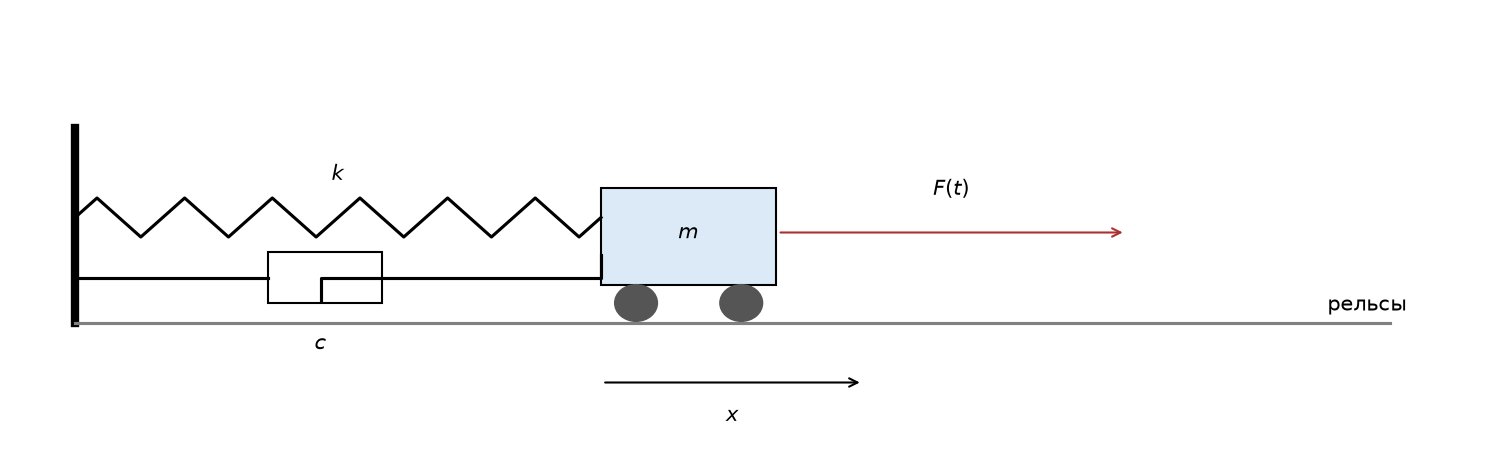

Стрелки координат задают положительное направление смещений от равновесия. Стрелка силы показывает её положительное направление; знак силы может меняться.

## Общая модель: силы и координата

$x(t)$ — смещение от положения равновесия **без внешней силы**, как в ДЗ № 5.
Ось направлена от стены. Поэтому удлинение пружины равно $x$, а не полной
длине пружины. Сила упругости $-kx$ возвращает тележку к $x=0$.
Сила вязкого сопротивления $-cx'$ направлена против скорости, а не против координаты.
Внешняя сила $F(t)$ положительна, когда направлена вправо.
Тяжесть и реакция опоры взаимно компенсируются.

По второму закону Ньютона сумма горизонтальных сил равна массе на ускорение:
$$mx''=-kx-cx'+F(t),\qquad mx''+cx'+kx=F(t).$$
Здесь $mx''$ — масса на ускорение; $cx'$ — перенесённый влево член сопротивления;
$kx$ — перенесённый влево упругий член. Каждый член имеет размерность силы:
$[m]=\mathrm{кг}$, $[c]=\mathrm{кг/с}$, $[k]=\mathrm{Н/м}$,
$[x]=\mathrm{м}$, $[F]=\mathrm{Н}$.

Для обеих моделей: $m=1$ кг, $c=2$ кг/с, $k=5$ Н/м,
$F_0=1$ Н, $x(0)=x_0=0{,}1$ м, $x'(0)=v_0=0$ м/с,
$t\in[0,15]$ с. Положительное сопротивление обеспечивает затухание переходной
части; числа выбраны для простых характеристических корней. Частотного
сканирования и исследования резонанса в этом ДЗ нет.

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

t = sp.symbols('t', real=True)
x = sp.Function('x')
m, c, k, F0 = 1, 2, 5, 1
x0, v0 = sp.Rational(1, 10), 0
tt = np.linspace(0, 15, 1501)

## Задача 1. Модель A: постоянная внешняя сила

**Постановка.** При $t\geq0$ на тележку действует $F(t)=F_0$; движение до
$t=0$ не рассматриваем. Начальные условия заданы независимо от включения силы.
Уравнение $mx''+cx'+kx=F_0$ следует из общей суммы сил.

### Подзадачи
1. Запишите второй закон Ньютона с тремя силами и подставьте параметры.
2. Решите соответствующее ЛОДУ: запишите характеристическое уравнение,
   найдите корни и общее решение $x_h(t)$.
3. Выберите пробное частное решение для постоянной правой части.
   Подставьте его и определите неизвестный коэффициент.
4. Соберите $x=x_h+x_p$. Вычислите $x'$, найдите обе постоянные из $x_0,v_0$.
5. Постройте `sp.Eq` и независимо решите через `dsolve` с начальными условиями.
   Проверьте равенство ответов через `simplify`, затем проверьте невязку исходного
   ДУ и оба начальных условия. Невязка — левая часть минус правая.
6. Получите скорость дифференцированием. Постройте $x(t)$ и $x'(t)$
   на двух графиках. На графике координаты отметьте найденное равновесие.
7. Найдите новое положение равновесия из баланса сил при нулевых скорости
   и ускорении. Выделите переходную часть и объясните её исчезновение.

**Вопросы.** Почему в равновесии вязкое трение не влияет на смещение?
К чему стремятся координата и скорость? Может ли тележка проходить через
новое положение равновесия? Почему постоянная сила не означает постоянную скорость?

In [2]:
# TODO: Enter the manually derived equation and solution for model A.
# TODO: Check with dsolve, then assert the residual and both initial conditions.
# TODO: Differentiate, lambdify and plot position and velocity with SI units.

## Задача 2. Модель B: гармоническая внешняя сила

**Постановка.** Теперь $F(t)=F_0\cos(\Omega t)$ при $t\geq0$.
Из второго закона Ньютона получаем $mx''+cx'+kx=F_0\cos(\Omega t)$.
Параметры и начальные условия те же. Сначала используйте $\Omega=1$ рад/с,
затем сравните $\Omega=1/2,\ 1,\ 3/2$ рад/с.

### Подзадачи
1. Запишите силы и уравнение с числами; решите соответствующее ЛОДУ.
2. Ищите $x_p=A\cos(\Omega t)+B\sin(\Omega t)$.
   Покажите обе производные, подстановку и систему на $A,B$.
   Нельзя оставлять только косинус: сопротивление смешивает синус и косинус.
3. Найдите $A,B$; составьте полное решение и определите $C_1,C_2$ по начальным
   условиям. Учитывайте вклад $x_p$ **в оба** начальных условия.
4. Проверьте результат SymPy: независимое `dsolve`, невязка уравнения,
   значение координаты и скорости при $t=0$.
5. Для трёх частот постройте $x(t)$ на одном графике, скорости — на другом.
   Для $\Omega=1$ отдельно сравните полное решение с установившейся частью $x_p$.
6. Постройте фазовые траектории: по горизонтали $x(t)$, по вертикали $x'(t)$,
   отдельная кривая на каждую частоту. Отметьте начальную точку.
7. Подпишите оси с единицами, добавьте сетку, легенды и заголовки на русском.
   Не соединяйте значения скорости с отсортированными координатами: обе
   координаты фазовой кривой должны идти в одном порядке времени.

**Вопросы.** Какая часть исчезает со временем, а какая остаётся? Какой период
установившегося движения? Почему после исчезновения переходной части тележка
не останавливается, хотя трение положительно? Чем фазовая кривая отличается от
свободного затухающего движения из ДЗ № 5? Какие различия видны для трёх заданных частот?
Чем вынужденное движение отличается от смещения равновесия в модели A?

In [3]:
omegas = [sp.Rational(1, 2), sp.Integer(1), sp.Rational(3, 2)]
# TODO: Derive A and B by matching the cosine and sine coefficients.
# TODO: Determine the homogeneous constants for each frequency.
# TODO: Check all solutions and plot positions, velocities and phase curves.